# Outlier and Anomaly Detection in Python

**A hands-on, reproducible notebook:** generate a labeled 2D dataset, explore its distributions, apply **eight outlier-detection algorithms**, visualize their results, and compare precision, recall, and F1 scores.

**Methods:** Z-score, Modified Z-score (MAD), IQR, Mahalanobis distance, Isolation Forest, Local Outlier Factor (LOF), One-Class SVM, and DBSCAN.

**Learning objectives:** understand the mathematics, distinguish statistical from machine-learning approaches, and recognize where each method can fail.

> All abnormal labels in this exercise are *injected synthetic labels* used for evaluation. Actual anomaly-detection datasets often have no labels.

## 1. Environment and reproducibility

Dependencies: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`, `IPython`. The random seed is fixed for reproducibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import chi2
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
rng = np.random.default_rng(SEED)
OUT_DIR = Path('results')
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 105, 'axes.grid': True, 'grid.alpha': 0.20})
print('Libraries loaded. Output folder:', OUT_DIR.resolve())

Libraries loaded. Output folder: /mnt/data/outlier_detection_project/results


## 2. Build a dataset with normal observations and injected anomalies

We simulate **600 inliers** in three clusters, and **60 injected anomalies** distributed across a larger region. Each row contains two numeric features plus a known evaluation label:

- `feature_1`, `feature_2`: numeric input variables.
- `is_anomaly`: `0` = generated inlier, `1` = injected anomaly.

The label is **not** used as an input feature to any detector. Some injected anomalies may fall near an ordinary cluster, making them intrinsically hard to detect.

In [2]:
X_normal, _ = make_blobs(
    n_samples=600,
    centers=[(-2.2, -1.0), (0.1, 2.8), (2.6, -1.3)],
    cluster_std=[0.64, 0.71, 0.69],
    random_state=SEED,
)
X_injected = rng.uniform(low=-8.0, high=8.0, size=(60, 2))
X_all = np.vstack([X_normal, X_injected])
y_true = np.r_[np.zeros(len(X_normal), dtype=int),
               np.ones(len(X_injected), dtype=int)]

data = pd.DataFrame(X_all, columns=['feature_1', 'feature_2'])
data['is_anomaly'] = y_true
# Shuffle the rows so that anomaly observations are not all at the end.
data = data.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
FEATURES = ['feature_1', 'feature_2']
X = data[FEATURES].copy()
y_true = data['is_anomaly'].to_numpy(dtype=int)
print('Dataset shape:', data.shape)
print('Generated anomalies:', y_true.sum())

Dataset shape: (660, 3)
Generated anomalies: 60


In [3]:
print('First 8 observations:')
display(data.head(8))
print('Summary statistics:')
display(data[FEATURES].describe().round(3))
print('Missing values:', data.isna().sum().to_dict())
print('Label distribution:', data['is_anomaly'].value_counts().sort_index().to_dict())
assert data[FEATURES].notna().all().all()
assert set(np.unique(y_true)) == {0, 1}

First 8 observations:


,feature_1,feature_2,is_anomaly
0,-5.763248,-6.167519,1
1,2.359430,-1.540988,0
2,0.851481,1.551295,0
3,-3.192425,-0.956120,0
4,-1.589439,-0.583110,0
5,-1.971016,-0.641098,0
6,0.249822,2.731334,0
7,-0.091279,3.309455,0


Summary statistics:


,feature_1,feature_2
count,660.000,660.000
mean,0.148,0.198
std,2.404,2.304
min,-7.637,-7.882
25%,-1.878,-1.359
50%,0.073,-0.621
75%,2.364,2.378
max,7.531,7.610


Missing values: {'feature_1': 0, 'feature_2': 0, 'is_anomaly': 0}
Label distribution: {0: 600, 1: 60}


In [4]:
dataset_path = Path('synthetic_anomaly_dataset.csv')
data.to_csv(dataset_path, index=False)
print('Saved dataset:', dataset_path.resolve())

Saved dataset: /mnt/data/outlier_detection_project/synthetic_anomaly_dataset.csv


## 3. Exploratory visualization: what is an outlier?

A point may be anomalous because of an extreme **single feature**, an unusual **combination of features**, or isolation from its neighbors. The plots below show these complementary views.

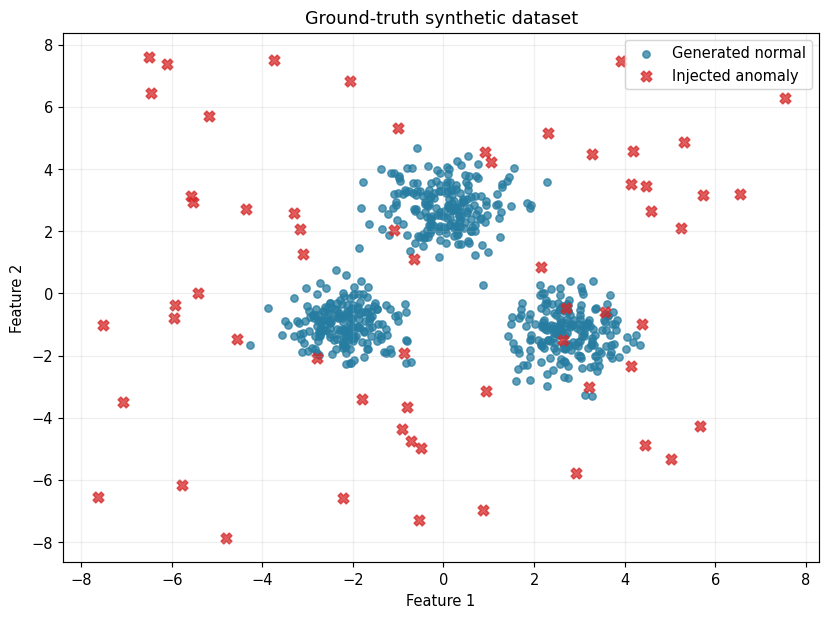

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, marker, name in [
    (0, '#277da1', 'o', 'Generated normal'),
    (1, '#d62828', 'X', 'Injected anomaly'),
]:
    subset = data[data['is_anomaly'] == label]
    ax.scatter(subset['feature_1'], subset['feature_2'],
               s=25 if label == 0 else 55, alpha=0.75,
               color=color, marker=marker, label=name)
ax.set(title='Ground-truth synthetic dataset', xlabel='Feature 1', ylabel='Feature 2')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / '01_ground_truth.png', bbox_inches='tight')
plt.show()

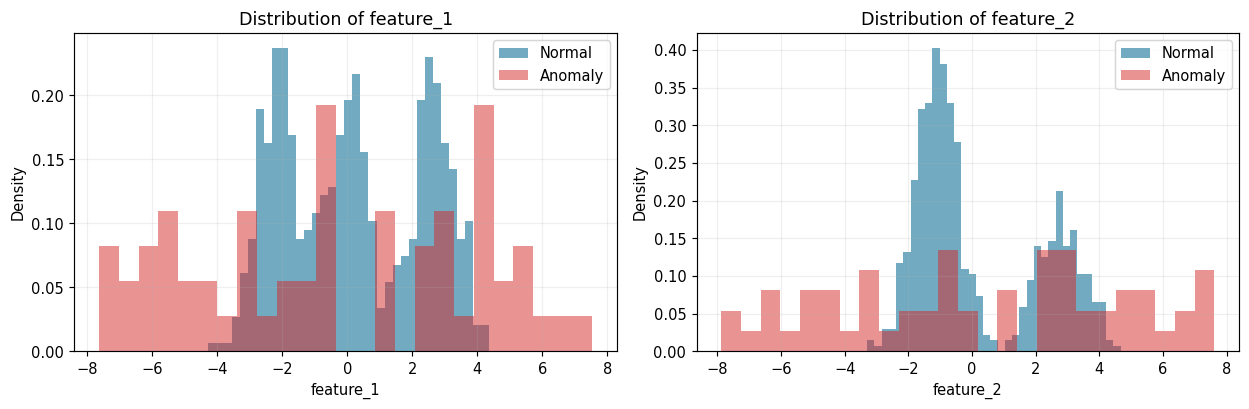

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, FEATURES):
    ax.hist(data.loc[y_true == 0, feature], bins=35, color='#277da1',
            alpha=0.65, label='Normal', density=True)
    ax.hist(data.loc[y_true == 1, feature], bins=25, color='#d62828',
            alpha=0.50, label='Anomaly', density=True)
    ax.set(title=f'Distribution of {feature}', xlabel=feature, ylabel='Density')
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / '02_feature_histograms.png', bbox_inches='tight')
plt.show()

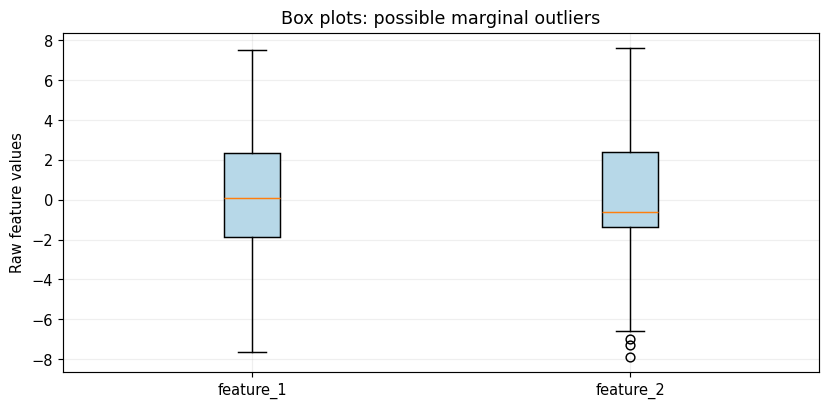

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([data[c].values for c in FEATURES], tick_labels=FEATURES,
           patch_artist=True, boxprops={'facecolor': '#b7d8e8'})
ax.set(title='Box plots: possible marginal outliers', ylabel='Raw feature values')
plt.tight_layout()
plt.savefig(OUT_DIR / '03_boxplots.png', bbox_inches='tight')
plt.show()

## 4. Standardization

Algorithms based on Euclidean distance or kernels can be dominated by features measured on a larger scale. Standardization transforms each feature using

$$
z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j},
$$

where $\mu_j$ and $\sigma_j$ are the mean and population standard deviation of feature $j$. We fit the scaler to **features only**, never the evaluation label.

> In real applications, split training and evaluation data first and fit scalers/models only on appropriate training data. This notebook focuses on unsupervised detection on a single dataset.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Original means:', X.mean().round(3).to_dict())
print('Scaled means:  ', np.round(X_scaled.mean(axis=0), 5))
print('Scaled SD:     ', np.round(X_scaled.std(axis=0), 5))

Original means: {'feature_1': 0.148, 'feature_2': 0.198}
Scaled means:   [-0.  0.]
Scaled SD:      [1. 1.]


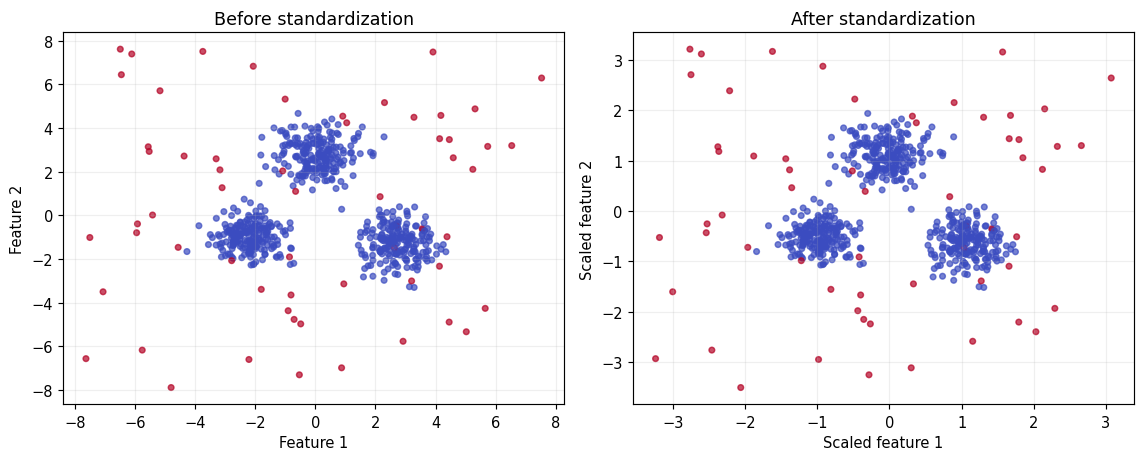

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_true, cmap='coolwarm', s=15, alpha=0.7)
axes[0].set(title='Before standardization', xlabel='Feature 1', ylabel='Feature 2')
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_true, cmap='coolwarm', s=15, alpha=0.7)
axes[1].set(title='After standardization', xlabel='Scaled feature 1', ylabel='Scaled feature 2')
plt.tight_layout()
plt.savefig(OUT_DIR / '04_scaling.png', bbox_inches='tight')
plt.show()

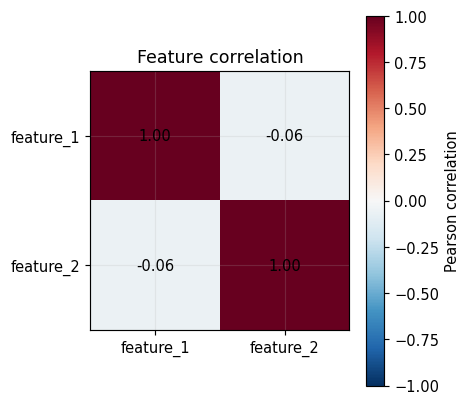

In [10]:
correlation = X.corr()
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f'{correlation.iloc[i,j]:.2f}', ha='center', va='center')
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Feature correlation')
plt.tight_layout()
plt.show()

## 5. Algorithm 1 — Z-score

For an observation $i$ and feature $j$,

$$Z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.$$

Flag a row when **any** feature exceeds the absolute threshold $t$:

$$\widehat y_i=\mathbf{1}\left[\max_j |Z_{ij}|>t\right].$$

We use $t=3$. **Limitation:** global means and standard deviations can be misleading with multimodal or contaminated data.

In [11]:
z_values = np.abs((X - X.mean()) / X.std(ddof=0))
z_score = z_values.max(axis=1).to_numpy()
z_pred = (z_score > 3.0).astype(int)
predictions = {'Z-score': z_pred}
print('Z-score flagged:', int(z_pred.sum()), 'of', len(z_pred))

Z-score flagged: 11 of 660


## 6. Algorithm 2 — Modified Z-score (median absolute deviation)

The robust median and median absolute deviation (MAD) are

$$m_j=\operatorname{median}_i(x_{ij}),\qquad
\operatorname{MAD}_j=\operatorname{median}_i|x_{ij}-m_j|.$$

The modified Z-score is

$$M_{ij}=\frac{0.6745(x_{ij}-m_j)}{\operatorname{MAD}_j}.$$

Flag a row if $\max_j|M_{ij}|>3.5$. MAD is less sensitive to extreme observations than the mean and standard deviation. A tiny constant protects against division by zero.

In [12]:
median = X.median()
mad = (X - median).abs().median().clip(lower=1e-12)
modified_z = (0.6745 * (X - median) / mad).abs()
mad_score = modified_z.max(axis=1).to_numpy()
mad_pred = (mad_score > 3.5).astype(int)
predictions['Modified Z (MAD)'] = mad_pred
print('Modified Z-score flagged:', int(mad_pred.sum()))

Modified Z-score flagged: 15


## 7. Algorithm 3 — Interquartile range (IQR)

For each feature, compute

$$\operatorname{IQR}_j=Q_{3,j}-Q_{1,j}.$$

The usual Tukey fences are

$$L_j=Q_{1,j}-1.5\operatorname{IQR}_j, \qquad
U_j=Q_{3,j}+1.5\operatorname{IQR}_j.$$

A row is flagged if any feature falls below $L_j$ or above $U_j$. This method also examines each feature separately.

In [13]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_pred = ((X.lt(lower)) | (X.gt(upper))).any(axis=1).to_numpy(dtype=int)
predictions['IQR'] = iqr_pred
print('Tukey fences:')
display(pd.DataFrame({'lower': lower, 'upper': upper}).round(3))
print('IQR flagged:', int(iqr_pred.sum()))

Tukey fences:


,lower,upper
feature_1,-8.241,8.727
feature_2,-6.965,7.984


IQR flagged: 3


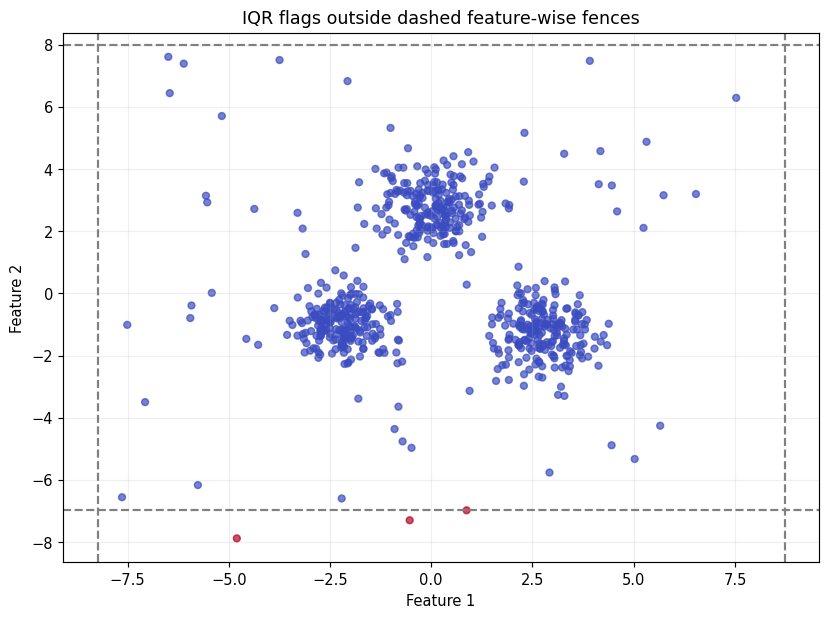

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X['feature_1'], X['feature_2'], c=iqr_pred, cmap='coolwarm', s=22, alpha=0.7)
ax.axvline(lower['feature_1'], ls='--', c='gray')
ax.axvline(upper['feature_1'], ls='--', c='gray')
ax.axhline(lower['feature_2'], ls='--', c='gray')
ax.axhline(upper['feature_2'], ls='--', c='gray')
ax.set(title='IQR flags outside dashed feature-wise fences',
       xlabel='Feature 1', ylabel='Feature 2')
plt.tight_layout()
plt.show()

## 8. Algorithm 4 — Mahalanobis distance

Unlike univariate thresholds, Mahalanobis distance accounts for the covariance between features:

$$D_i^2=(\mathbf{x}_i-\boldsymbol{\mu})^T
\boldsymbol{\Sigma}^{-1}(\mathbf{x}_i-\boldsymbol{\mu}).$$

For a *single multivariate normal distribution* of $p$ features, $D_i^2$ approximately follows a $\chi^2_p$ distribution. We flag observations when

$$D_i^2>\chi^2_{p,0.99}.$$

**Important:** the three-cluster distribution here is not multivariate normal, so the chi-square threshold is a teaching approximation, **not a calibrated 1% false-alarm guarantee**.

In [15]:
x_array = X.to_numpy()
mu = x_array.mean(axis=0)
cov_inv = np.linalg.pinv(np.cov(x_array, rowvar=False))
delta = x_array - mu
mahal_squared = np.einsum('ij,jk,ik->i', delta, cov_inv, delta)
mahal_threshold = chi2.ppf(0.99, df=x_array.shape[1])
mahal_pred = (mahal_squared > mahal_threshold).astype(int)
predictions['Mahalanobis'] = mahal_pred
print(f'Mahalanobis squared-distance threshold: {mahal_threshold:.3f}')
print('Mahalanobis flagged:', int(mahal_pred.sum()))

Mahalanobis squared-distance threshold: 9.210
Mahalanobis flagged: 17


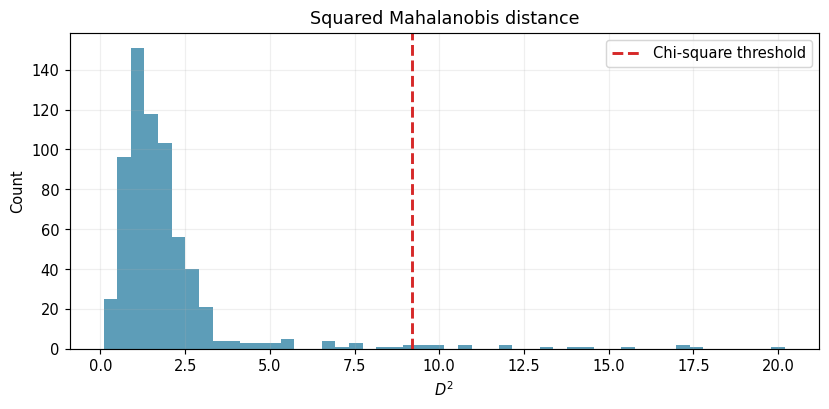

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mahal_squared, bins=50, color='#277da1', alpha=0.75)
ax.axvline(mahal_threshold, color='#d62828', ls='--', lw=2, label='Chi-square threshold')
ax.set(title='Squared Mahalanobis distance', xlabel=r'$D^2$', ylabel='Count')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Algorithm 5 — Isolation Forest

Isolation Forest recursively separates points using random feature splits. Rare, isolated observations tend to require shorter paths. Its theoretical anomaly score can be written as

$$s(\mathbf{x},n)=2^{-E[h(\mathbf{x})]/c(n)},$$

where $h$ is isolation path length and $c(n)$ normalizes the expected path length. A higher $s$ indicates a more anomalous point.

Below, scikit-learn's `decision_function` gives values **above zero for inliers and below zero for outliers**, so we negate it to obtain an intuitive "larger = more anomalous" score. The `contamination` parameter sets the estimated share of anomalies; here the synthetic benchmark's injected proportion is used for illustration.

In [17]:
contamination = float(y_true.mean())   # known only because this is a synthetic benchmark
iso_model = IsolationForest(n_estimators=200, contamination=contamination,
                            random_state=SEED, n_jobs=-1)
iso_raw = iso_model.fit_predict(X_scaled)  # -1 = anomaly, +1 = normal
iso_pred = (iso_raw == -1).astype(int)
iso_score = -iso_model.decision_function(X_scaled)
predictions['Isolation Forest'] = iso_pred
print('Isolation Forest flagged:', int(iso_pred.sum()))

Isolation Forest flagged: 60


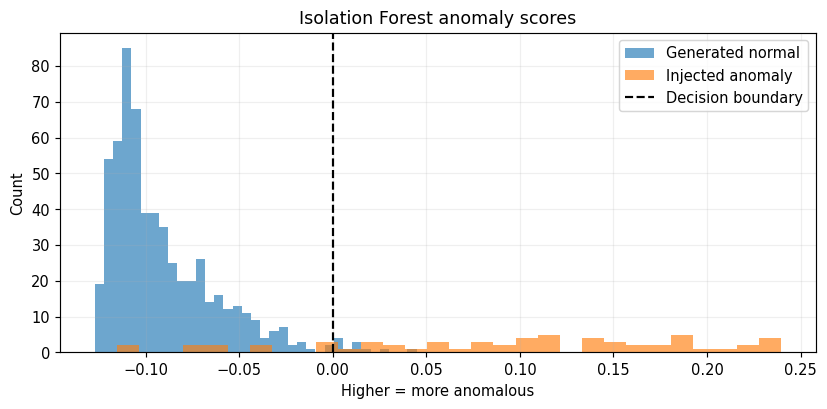

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(iso_score[y_true == 0], bins=35, alpha=0.65, label='Generated normal')
ax.hist(iso_score[y_true == 1], bins=30, alpha=0.65, label='Injected anomaly')
ax.axvline(0, ls='--', c='black', label='Decision boundary')
ax.set(title='Isolation Forest anomaly scores', xlabel='Higher = more anomalous', ylabel='Count')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Algorithm 6 — Local Outlier Factor (LOF)

LOF compares a point's local density with its neighbors'. For $k$ nearest neighbors $N_k(p)$, reachability distance is

$$\operatorname{reachdist}_k(p,o)=\max\{k\text{-distance}(o),d(p,o)\}.$$

Local reachability density and the LOF score are

$$\operatorname{lrd}_k(p)=\left(\frac{1}{|N_k(p)|}
\sum_{o\in N_k(p)}\operatorname{reachdist}_k(p,o)\right)^{-1},$$

$$\operatorname{LOF}_k(p)=\frac{1}{|N_k(p)|}\sum_{o\in N_k(p)}
\frac{\operatorname{lrd}_k(o)}{\operatorname{lrd}_k(p)}.$$

Scores near 1 indicate a density similar to neighbors; larger scores suggest outliers. `fit_predict` works for this training dataset (LOF's default novelty mode).

In [19]:
lof_model = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
lof_raw = lof_model.fit_predict(X_scaled)
lof_pred = (lof_raw == -1).astype(int)
lof_score = -lof_model.negative_outlier_factor_
predictions['LOF'] = lof_pred
print('LOF flagged:', int(lof_pred.sum()))

LOF flagged: 60


## 11. Algorithm 7 — One-Class Support Vector Machine

A kernel One-Class SVM learns a boundary around typical data. Its prediction function is

$$f(\mathbf{x})=\sum_{i=1}^{n}\alpha_i K(\mathbf{x}_i,\mathbf{x})-\rho,$$

where $K$ is a kernel. A new point is considered anomalous when $f(\mathbf{x})<0$. With the radial-basis-function (RBF) kernel,

$$K(\mathbf{x},\mathbf{z})=\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|_2^2).$$

`nu` controls an upper bound on the fraction of training errors and a lower bound on the fraction of support vectors (under standard assumptions); it is **not** a guarantee of exactly that many anomalies.

In [20]:
svm_model = OneClassSVM(kernel='rbf', gamma='scale', nu=contamination)
svm_raw = svm_model.fit_predict(X_scaled)
svm_pred = (svm_raw == -1).astype(int)
svm_score = -svm_model.decision_function(X_scaled).ravel()
predictions['One-Class SVM'] = svm_pred
print('One-Class SVM flagged:', int(svm_pred.sum()))

One-Class SVM flagged: 61


## 12. Algorithm 8 — DBSCAN (density-based clustering)

DBSCAN groups points in dense regions and labels unassigned points as noise. Its $\varepsilon$-neighborhood is

$$N_\varepsilon(p)=\{q:\|p-q\|_2\le\varepsilon\}.$$

A **core point** satisfies

$$|N_\varepsilon(p)|\ge\operatorname{min\_samples}.$$

A point that cannot be reached from any core point is marked as noise (`-1`); we treat this noise as anomalies. The values of `eps` and `min_samples` need tuning for the scale and density of your data.

In [21]:
dbscan_model = DBSCAN(eps=0.31, min_samples=10)
dbscan_cluster_labels = dbscan_model.fit_predict(X_scaled)
dbscan_pred = (dbscan_cluster_labels == -1).astype(int)
predictions['DBSCAN'] = dbscan_pred
cluster_ids = np.unique(dbscan_cluster_labels[dbscan_cluster_labels != -1])
print('DBSCAN cluster labels (excluding noise):', cluster_ids.tolist())
print('DBSCAN noise points:', int(dbscan_pred.sum()))

DBSCAN cluster labels (excluding noise): [0, 1, 2]
DBSCAN noise points: 51


## 13. Compare detectors visually

Each panel below colors **predicted outliers in red** and predicted normal points in blue. Compare with the earlier ground-truth plot. The predictions are not expected to agree perfectly because the detectors define "unusual" in different ways.

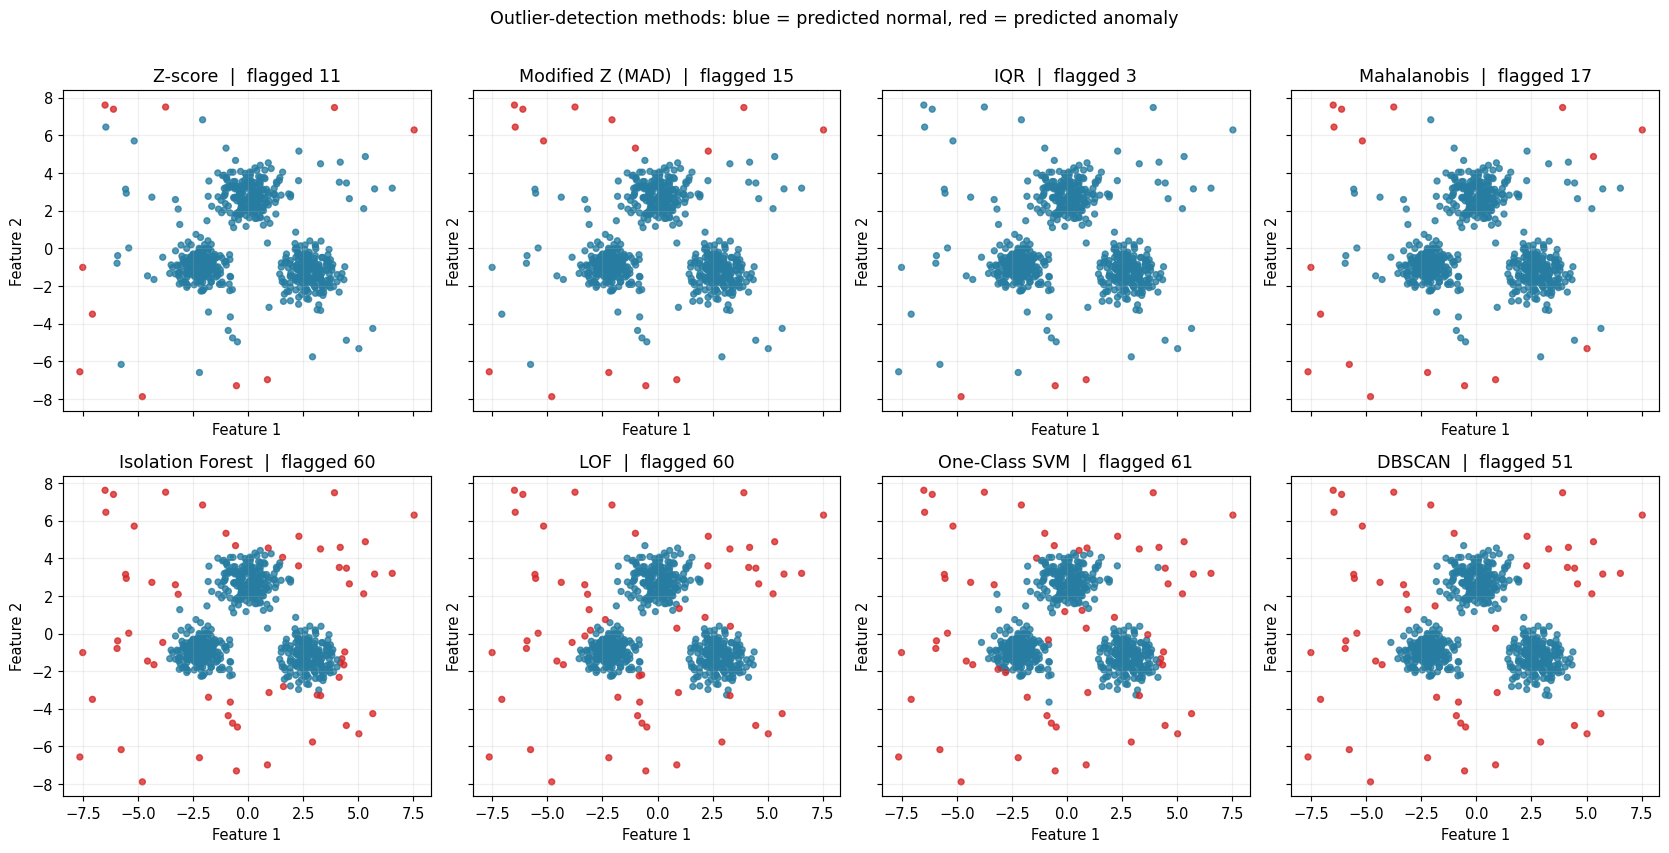

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(X['feature_1'], X['feature_2'], c=np.where(pred == 1, '#d62828', '#277da1'),
               s=16, alpha=0.78)
    ax.set_title(f'{name}  |  flagged {int(pred.sum())}')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
fig.suptitle('Outlier-detection methods: blue = predicted normal, red = predicted anomaly', y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / '05_eight_detector_comparison.png', bbox_inches='tight')
plt.show()

In [23]:
counts = pd.Series({name: int(pred.sum()) for name, pred in predictions.items()},
                   name='Predicted outliers')
print('Actual injected anomalies:', int(y_true.sum()))
display(counts.to_frame())

Actual injected anomalies: 60


,Predicted outliers
Z-score,11
Modified Z (MAD),15
IQR,3
Mahalanobis,17
Isolation Forest,60
LOF,60
One-Class SVM,61
DBSCAN,51


## 14. Evaluation mathematics (synthetic labeled data only)

We can compare the predicted labels $\widehat y$ with the injected ground truth $y$. Define:

- **TP:** actual outlier predicted outlier
- **FP:** actual normal predicted outlier
- **FN:** actual outlier predicted normal
- **TN:** actual normal predicted normal

Then

$$\operatorname{Precision}=\frac{TP}{TP+FP},\qquad
\operatorname{Recall}=\frac{TP}{TP+FN},$$

$$F_1=2\frac{\operatorname{Precision}\cdot\operatorname{Recall}}
{\operatorname{Precision}+\operatorname{Recall}}=\frac{2TP}{2TP+FP+FN}.$$

**Interpretation:** precision penalizes false alarms, recall penalizes missed anomalies, and F1 balances the two. These metrics require reliable labels, which many real anomaly datasets lack.

In [24]:
metric_rows = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    metric_rows.append({
        'Algorithm': name,
        'Flagged': int(pred.sum()), 'TP': int(tp), 'FP': int(fp),
        'FN': int(fn), 'TN': int(tn),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
    })
metrics = pd.DataFrame(metric_rows).sort_values('F1', ascending=False).reset_index(drop=True)
print('Sorted by F1 (this dataset only):')
display(metrics.round(3))

Sorted by F1 (this dataset only):


,Algorithm,Flagged,TP,FP,FN,TN,Precision,Recall,F1
0,DBSCAN,51,47,4,13,596,0.922,0.783,0.847
1,Isolation Forest,60,49,11,11,589,0.817,0.817,0.817
2,LOF,60,48,12,12,588,0.800,0.800,0.800
3,One-Class SVM,61,47,14,13,586,0.770,0.783,0.777
4,Mahalanobis,17,17,0,43,600,1.000,0.283,0.442
5,Modified Z (MAD),15,15,0,45,600,1.000,0.250,0.400
6,Z-score,11,11,0,49,600,1.000,0.183,0.310
7,IQR,3,3,0,57,600,1.000,0.050,0.095


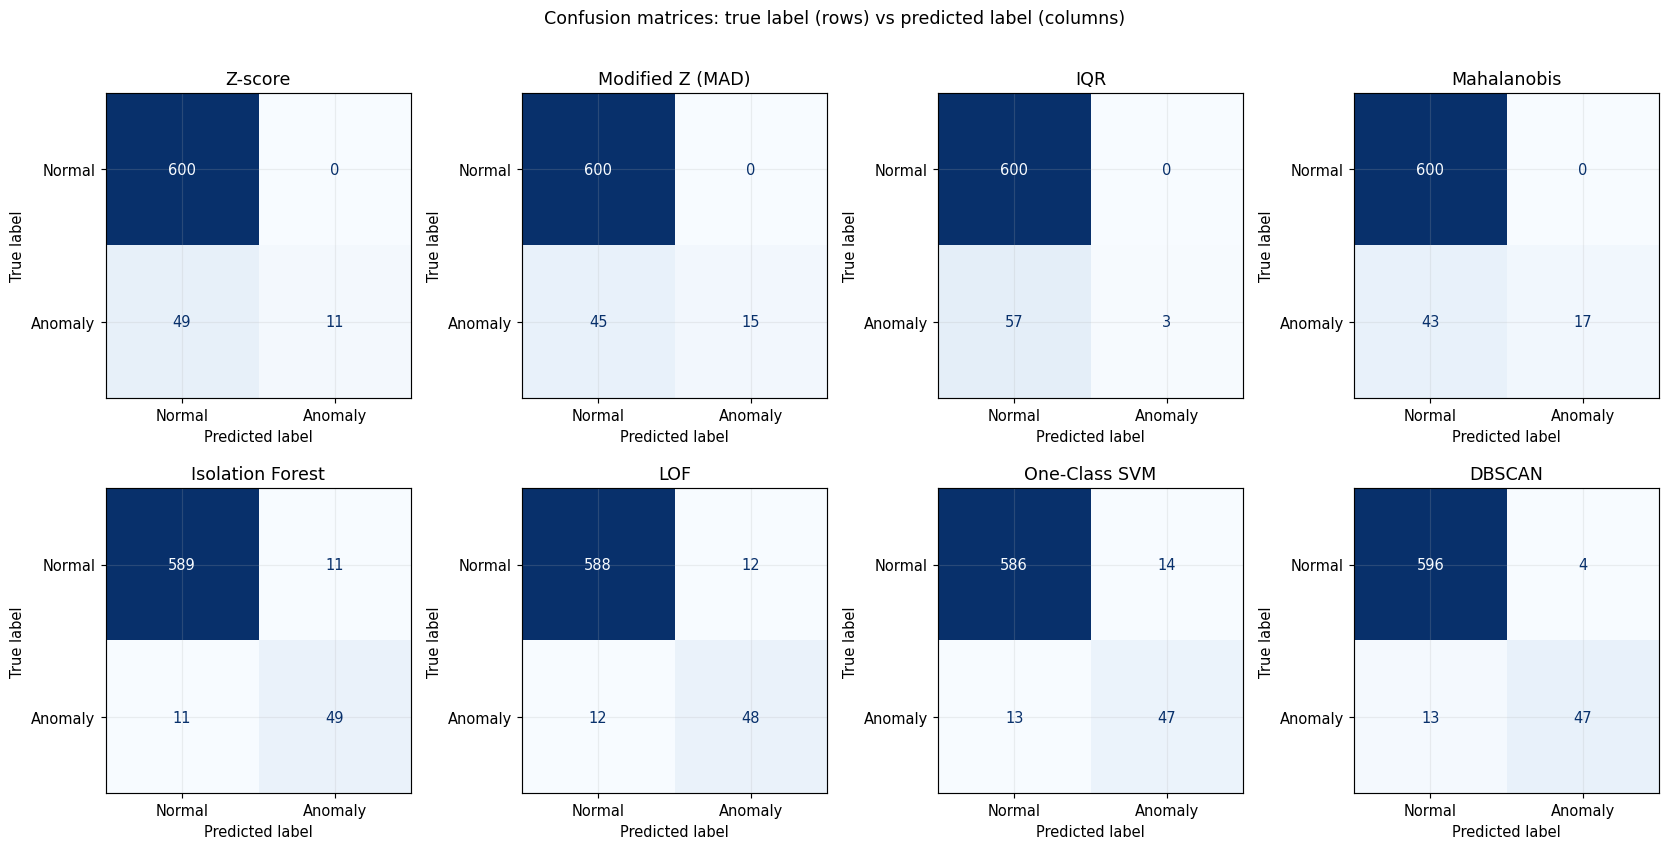

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_true, pred, labels=[0, 1],
                                            display_labels=['Normal', 'Anomaly'],
                                            cmap='Blues', colorbar=False, ax=ax,
                                            values_format='d')
    ax.set_title(name)
fig.suptitle('Confusion matrices: true label (rows) vs predicted label (columns)', y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / '06_confusion_matrices.png', bbox_inches='tight')
plt.show()

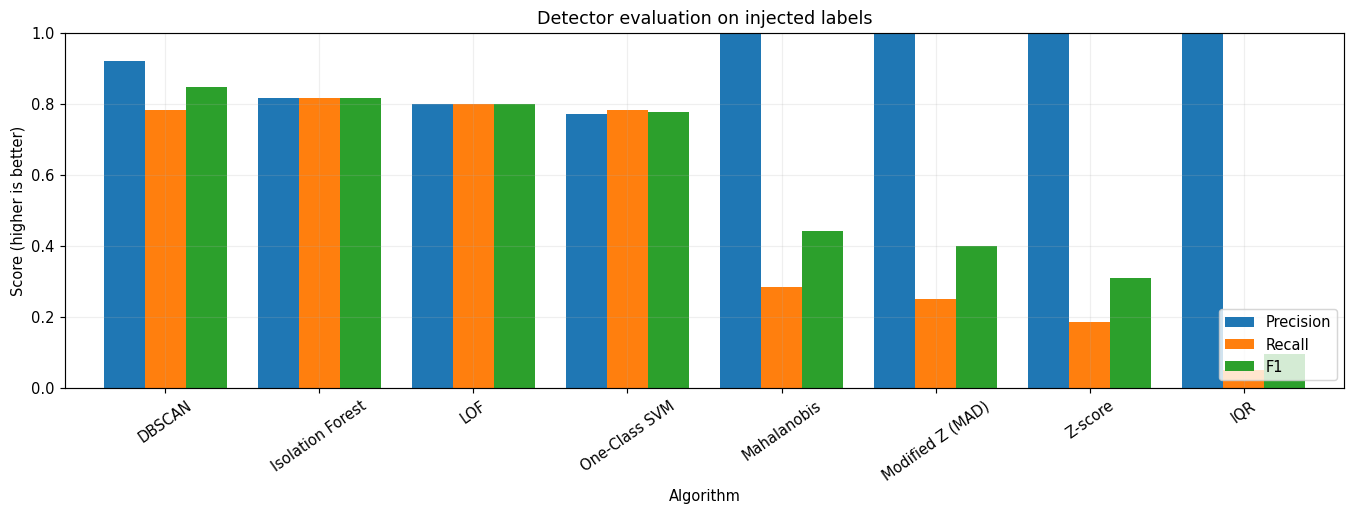

In [26]:
plot_df = metrics.set_index('Algorithm')[['Precision', 'Recall', 'F1']]
ax = plot_df.plot(kind='bar', figsize=(13, 5), ylim=(0, 1), rot=35, width=0.8)
ax.set(title='Detector evaluation on injected labels', ylabel='Score (higher is better)',
       xlabel='Algorithm')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(OUT_DIR / '07_algorithm_metrics.png', bbox_inches='tight')
plt.show()

## 15. Sensitivity analysis: Isolation Forest contamination

Different assumptions about the fraction of anomalous points change the detector's threshold. Here we refit Isolation Forest with a range of **assumed** contamination values and compare to the synthetic ground truth. In production, choose or estimate this value from domain knowledge or validation data, not from unavailable true labels.

In [27]:
contamination_grid = [0.03, 0.05, 0.07, 0.09, 0.12, 0.16, 0.20]
sensitivity = []
for c in contamination_grid:
    model = IsolationForest(n_estimators=150, contamination=c, random_state=SEED, n_jobs=-1)
    guess = (model.fit_predict(X_scaled) == -1).astype(int)
    sensitivity.append({'Assumed contamination': c,
                        'Flagged': int(guess.sum()),
                        'Precision': precision_score(y_true, guess, zero_division=0),
                        'Recall': recall_score(y_true, guess, zero_division=0),
                        'F1': f1_score(y_true, guess, zero_division=0)})
sensitivity_df = pd.DataFrame(sensitivity)
display(sensitivity_df.round(3))

,Assumed contamination,Flagged,Precision,Recall,F1
0,0.03,20,1.000,0.333,0.500
1,0.05,33,1.000,0.550,0.710
2,0.07,47,0.979,0.767,0.860
3,0.09,60,0.817,0.817,0.817
4,0.12,80,0.650,0.867,0.743
5,0.16,106,0.500,0.883,0.639
6,0.20,132,0.402,0.883,0.552


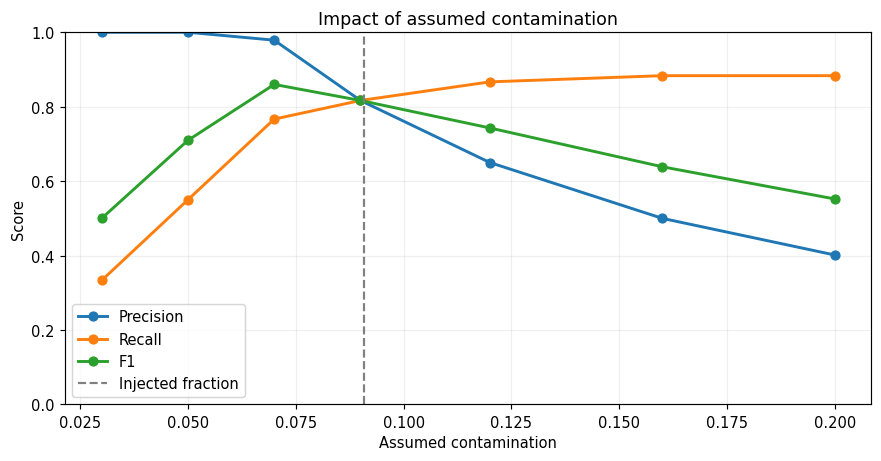

In [28]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for column in ['Precision', 'Recall', 'F1']:
    ax.plot(sensitivity_df['Assumed contamination'], sensitivity_df[column],
            marker='o', lw=2, label=column)
ax.axvline(contamination, ls='--', c='gray', label='Injected fraction')
ax.set(title='Impact of assumed contamination', xlabel='Assumed contamination',
       ylabel='Score', ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / '08_contamination_sensitivity.png', bbox_inches='tight')
plt.show()

## 16. Inspect the most unusual observations

Rank observations by Isolation Forest's anomaly score (`-decision_function`). The score is a **relative ranking**, not a probability that the sample is bad.

In [29]:
results = data.copy()
for name, pred in predictions.items():
    results['pred_' + name.lower().replace(' ', '_').replace('-', '_').replace('(', '').replace(')', '')] = pred
results['isolation_forest_anomaly_score'] = iso_score
results['lof_anomaly_score'] = lof_score
results['mahalanobis_squared_distance'] = mahal_squared
top12 = results.nlargest(12, 'isolation_forest_anomaly_score')
display(top12[['feature_1', 'feature_2', 'is_anomaly',
               'isolation_forest_anomaly_score', 'lof_anomaly_score']].round(3))

,feature_1,feature_2,is_anomaly,isolation_forest_anomaly_score,lof_anomaly_score
572,-7.637,-6.559,1,0.240,6.531
226,-6.493,7.610,1,0.234,4.292
439,7.531,6.290,1,0.232,3.410
418,-4.801,-7.882,1,0.229,5.034
528,-6.112,7.390,1,0.222,4.159
619,-6.458,6.442,1,0.218,3.916
0,-5.763,-6.168,1,0.213,5.112
404,-3.746,7.507,1,0.201,4.016
374,-7.067,-3.498,1,0.191,4.938
537,3.916,7.480,1,0.187,3.582


In [30]:
results.to_csv(OUT_DIR / 'all_detector_predictions.csv', index=False)
metrics.to_csv(OUT_DIR / 'algorithm_metrics.csv', index=False)
sensitivity_df.to_csv(OUT_DIR / 'contamination_sensitivity.csv', index=False)
top12.to_csv(OUT_DIR / 'top12_anomalies.csv', index=False)
print('Saved prediction tables, evaluation metrics, sensitivity results, and top anomalies.')
print('Output files:')
for path in sorted(OUT_DIR.glob('*')):
    print(' -', path)

Saved prediction tables, evaluation metrics, sensitivity results, and top anomalies.
Output files:
 - results/01_ground_truth.png
 - results/02_feature_histograms.png
 - results/03_boxplots.png
 - results/04_scaling.png
 - results/05_eight_detector_comparison.png
 - results/06_confusion_matrices.png
 - results/07_algorithm_metrics.png
 - results/08_contamination_sensitivity.png
 - results/algorithm_metrics.csv
 - results/all_detector_predictions.csv
 - results/contamination_sensitivity.csv
 - results/top12_anomalies.csv


## 17. Conclusions and practical guidance

**What to notice:**

1. **Z-score, Modified Z-score, IQR:** quick, interpretable baselines, but independent feature thresholds miss some unusual combinations.
2. **Mahalanobis:** models correlated variables, but a single covariance model can be unsuitable for multiple clusters; its chi-square cutoff assumes a specific distribution.
3. **Isolation Forest:** a strong general-purpose option for tabular outlier ranking; contamination controls the cutoff.
4. **LOF:** detects low local density, useful when clusters have different densities; its default training mode is not for predicting on new observations without refitting.
5. **One-Class SVM:** learns a nonlinear boundary; scaling and hyperparameters matter.
6. **DBSCAN:** identifies noise in sparse regions; its `eps` should match data scale and density.

**For your own dataset:** replace the synthetic-data creation cell with `pd.read_csv('your_file.csv')`, select numeric feature columns, handle missing values, and set `X` to those features. If ground-truth anomaly labels are unavailable, skip the evaluation cells; do not invent them. For time-series anomalies, use temporal features and time-aware validation instead of treating every row as independent.

**To run:** execute all cells in order. The notebook writes figures and CSV results to `results/`, and exports `synthetic_anomaly_dataset.csv` alongside the notebook. See `README.md` for installation commands.